<a href="https://colab.research.google.com/github/aswinpalraj77-coder/CodeAlpha_-Project-Management-Tool/blob/main/Mini%20project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install pandas numpy matplotlib networkx scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Step 2: Create the Research Paper Dataset

papers = [
    (1, "Neural Machine Translation with Attention",
     "A neural model translates text between languages using attention.", 2016, "NLP"),
    (2, "Sentiment Analysis of Social Media Text",
     "A language model classifies sentiment of reviews using word embeddings.", 2017, "NLP"),
    (3, "Transformer Language Models for Text Generation",
     "A transformer language model generates text and improves translation.", 2019, "NLP"),
    (4, "Question Answering over Documents",
     "A system reads documents and answers questions using text embeddings.", 2020, "NLP"),
    (5, "Named Entity Recognition in Text",
     "A sequence model finds names of people and places in text.", 2018, "NLP"),

    (6, "Convolutional Networks for Image Classification",
     "A deep convolutional network classifies images into object categories.", 2015, "Vision"),
    (7, "Object Detection in Real Time",
     "A fast detector locates and labels objects in images and video.", 2017, "Vision"),
    (8, "Image Segmentation with Deep Networks",
     "A deep network labels every pixel of an image for scene segmentation.", 2018, "Vision"),
    (9, "Face Recognition Using Deep Features",
     "A deep network learns facial features from images to recognize faces.", 2016, "Vision"),
    (10, "Vision Transformers for Images",
     "A transformer splits an image into patches and classifies it with attention.", 2021, "Vision"),

    (11, "Deep Q-Learning for Games",
     "An agent learns to play games by maximizing reward with deep Q-learning.", 2015, "RL"),
    (12, "Policy Gradient Methods for Control",
     "A policy gradient algorithm trains an agent to control a robot using reward.", 2017, "RL"),
    (13, "Multi-Agent Reinforcement Learning",
     "Several agents learn cooperative policies in a shared environment using reward.", 2019, "RL"),
    (14, "Reward Shaping for Robot Navigation",
     "An agent learns to navigate a robot using shaped reward and policy learning.", 2018, "RL"),
    (15, "Model-Based Reinforcement Learning",
     "An agent learns a model of the environment and plans actions to maximize reward.", 2020, "RL"),

    (16, "Deep Learning for Medical Imaging",
     "A deep network detects diseases in medical scans such as X-ray and MRI.", 2017, "Health"),
    (17, "Predicting Patient Readmission",
     "A machine learning model predicts patient readmission from clinical health records.", 2018, "Health"),
    (18, "Clinical Text Mining",
     "Language processing extracts diagnosis information from clinical notes of patients.", 2019, "Health"),
    (19, "Drug Discovery with Machine Learning",
     "A machine learning model predicts drug molecule properties for drug discovery.", 2020, "Health"),
    (20, "Early Disease Prediction from Health Records",
     "A model analyses patient health records to predict disease risk early.", 2021, "Health")
]

# Convert the list into a DataFrame
df = pd.DataFrame(
    papers,
    columns=["paper_id", "title", "abstract", "year", "topic"]
)

# Create citation relationships
citations = [
    (3,1), (3,2), (3,5), (4,1), (4,3), (4,5),
    (10,3), (7,6), (8,6), (8,7), (9,6), (10,6),
    (10,8), (12,11), (13,11), (13,12), (14,11),
    (14,12), (15,11), (15,12), (16,6), (16,8),
    (18,3), (18,5), (18,17), (19,16), (19,17),
    (20,16), (20,17), (20,18)
]

cites = pd.DataFrame(citations, columns=["citing", "cited"])

# Save both datasets as CSV files
df.to_csv("papers.csv", index=False)
cites.to_csv("citations.csv", index=False)

print("Research paper dataset created successfully!")
print("Total papers:", len(df))
print("Total citation links:", len(cites))

display(df.head())
display(cites.head())

Research paper dataset created successfully!
Total papers: 20
Total citation links: 30


,paper_id,title,abstract,year,topic
0,1,Neural Machine Translation with Attention,A neural model translates text between languag...,2016,NLP
1,2,Sentiment Analysis of Social Media Text,A language model classifies sentiment of revie...,2017,NLP
2,3,Transformer Language Models for Text Generation,A transformer language model generates text an...,2019,NLP
3,4,Question Answering over Documents,A system reads documents and answers questions...,2020,NLP
4,5,Named Entity Recognition in Text,A sequence model finds names of people and pla...,2018,NLP


,citing,cited
0,3,1
1,3,2
2,3,5
3,4,1
4,4,3


In [3]:

# Step 3: Load and Validate the Dataset

df = pd.read_csv("papers.csv")
cites = pd.read_csv("citations.csv")

# Display dataset size
print("Papers Dataset Shape:", df.shape)
print("Citations Dataset Shape:", cites.shape)

# Check column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Count papers in each topic
print("\nPapers Per Topic:")
print(df["topic"].value_counts())

# Display first five papers
print("\nFirst Five Research Papers:")
display(df[["paper_id", "title", "year", "topic"]].head())

Papers Dataset Shape: (20, 5)
Citations Dataset Shape: (30, 2)

Dataset Columns:
['paper_id', 'title', 'abstract', 'year', 'topic']

Missing Values:
paper_id    0
title       0
abstract    0
year        0
topic       0
dtype: int64

Papers Per Topic:
topic
NLP       5
Vision    5
RL        5
Health    5
Name: count, dtype: int64

First Five Research Papers:


,paper_id,title,year,topic
0,1,Neural Machine Translation with Attention,2016,NLP
1,2,Sentiment Analysis of Social Media Text,2017,NLP
2,3,Transformer Language Models for Text Generation,2019,NLP
3,4,Question Answering over Documents,2020,NLP
4,5,Named Entity Recognition in Text,2018,NLP


In [4]:

# Step 4: Combine Title and Abstract

df["content"] = (
    df["title"].fillna("") + " " +
    df["abstract"].fillna("")
)

# Display combined text
print("Title and Abstract Combined Successfully!")

display(df[["paper_id", "title", "content"]].head(5))

# Check the total number of research papers
print("\nTotal Research Papers:", len(df))

# Check for empty text
print("Empty Content Rows:", (df["content"].str.strip() == "").sum())

Title and Abstract Combined Successfully!


,paper_id,title,content
0,1,Neural Machine Translation with Attention,Neural Machine Translation with Attention A ne...
1,2,Sentiment Analysis of Social Media Text,Sentiment Analysis of Social Media Text A lang...
2,3,Transformer Language Models for Text Generation,Transformer Language Models for Text Generatio...
3,4,Question Answering over Documents,Question Answering over Documents A system rea...
4,5,Named Entity Recognition in Text,Named Entity Recognition in Text A sequence mo...



Total Research Papers: 20
Empty Content Rows: 0


In [5]:

# Step 5: TF-IDF Vectorization

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

# Convert paper text into numerical features
X = vectorizer.fit_transform(df["content"])

# Display results
print("TF-IDF Vectorization Completed!")
print("TF-IDF Matrix Shape:", X.shape)

# Display some important words learned by the model
print("\nFirst 20 Features:")
print(vectorizer.get_feature_names_out()[:20])

# Display numerical representation of the first paper
print("\nFirst Paper TF-IDF Vector:")
print(X[0].toarray())

TF-IDF Vectorization Completed!
TF-IDF Matrix Shape: (20, 128)

First 20 Features:
['actions' 'agent' 'agents' 'algorithm' 'analyses' 'analysis' 'answering'
 'answers' 'attention' 'based' 'categories' 'classification' 'classifies'
 'clinical' 'control' 'convolutional' 'cooperative' 'deep' 'detection'
 'detector']

First Paper TF-IDF Vector:
[[0.         0.         0.         0.         0.         0.
  0.         0.         0.51769021 0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.29447167 0.         0.         0.
  0.         0.23356766 0.         0.         0.         0.
  0.         0.         0.16231453 0.         0.         

In [6]:

# Step 6: Latent Semantic Analysis (LSA)

# Reduce TF-IDF features into 10 components
n_components = min(10, X.shape[0] - 1, X.shape[1] - 1)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

# Create semantic representations
X_lsa = normalize(svd.fit_transform(X))

print("LSA Transformation Completed!")
print("Original TF-IDF Shape:", X.shape)
print("LSA Matrix Shape:", X_lsa.shape)

# Display the first paper's semantic representation
print("\nFirst Paper LSA Representation:")
print(np.round(X_lsa[0], 3))

LSA Transformation Completed!
Original TF-IDF Shape: (20, 128)
LSA Matrix Shape: (20, 10)

First Paper LSA Representation:
[ 0.306 -0.148  0.553 -0.095 -0.274  0.436  0.495  0.151  0.021  0.192]


In [7]:

# Step 7: Build Semantic Search Engine

def search_papers(query, top_n=5):

    # Convert user query into TF-IDF features
    query_vector = vectorizer.transform([query])

    # Transform query using the trained LSA model
    query_lsa = normalize(svd.transform(query_vector))

    # Calculate cosine similarity with all papers
    scores = cosine_similarity(query_lsa, X_lsa)[0]

    # Get the most relevant paper indices
    best_indices = scores.argsort()[::-1][:top_n]

    # Prepare search results
    results = df.iloc[best_indices][
        ["paper_id", "title", "year", "topic"]
    ].copy()

    results["similarity_score"] = np.round(
        scores[best_indices], 3
    )

    return results.reset_index(drop=True)


# Test the search engine
search_results = search_papers(
    "agent learning with reward for robot control"
)

print("Semantic Search Results:")
display(search_results)

Semantic Search Results:


,paper_id,title,year,topic,similarity_score
0,14,Reward Shaping for Robot Navigation,2018,RL,0.995
1,12,Policy Gradient Methods for Control,2017,RL,0.876
2,11,Deep Q-Learning for Games,2015,RL,0.535
3,13,Multi-Agent Reinforcement Learning,2019,RL,0.467
4,15,Model-Based Reinforcement Learning,2020,RL,0.459


In [8]:

# Step 8: K-Means Clustering

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign a cluster to every research paper
df["cluster"] = kmeans.fit_predict(X_lsa)

print("K-Means Clustering Completed!")

# Display papers and their assigned clusters
display(
    df[["paper_id", "title", "topic", "cluster"]]
    .sort_values(["cluster", "paper_id"])
    .reset_index(drop=True)
)

# Evaluate clustering quality
unique_clusters = df["cluster"].nunique()

if 2 <= unique_clusters < len(df):
    score = silhouette_score(X_lsa, df["cluster"])
    print("\nSilhouette Score:", round(score, 3))
else:
    print("\nSilhouette Score cannot be calculated.")

K-Means Clustering Completed!


,paper_id,title,topic,cluster
0,11,Deep Q-Learning for Games,RL,0
1,12,Policy Gradient Methods for Control,RL,0
2,13,Multi-Agent Reinforcement Learning,RL,0
3,14,Reward Shaping for Robot Navigation,RL,0
4,15,Model-Based Reinforcement Learning,RL,0
5,1,Neural Machine Translation with Attention,NLP,1
6,2,Sentiment Analysis of Social Media Text,NLP,1
7,3,Transformer Language Models for Text Generation,NLP,1
8,4,Question Answering over Documents,NLP,1
9,5,Named Entity Recognition in Text,NLP,1



Silhouette Score: 0.186


In [9]:

# Step 9: Extract Important Keywords from Each Cluster

terms = np.array(vectorizer.get_feature_names_out())

for cluster_id in sorted(df["cluster"].unique()):

    # Select papers belonging to this cluster
    cluster_mask = (df["cluster"] == cluster_id).values

    # Calculate average TF-IDF score for each word
    centroid = X[cluster_mask].mean(axis=0).A1

    # Select the top 5 keywords
    top_indices = centroid.argsort()[::-1][:5]
    top_keywords = terms[top_indices]

    print(f"\nCluster {cluster_id}")
    print("Important Keywords:", ", ".join(top_keywords))

    # Display papers in this cluster
    cluster_papers = df.loc[cluster_mask, "title"].tolist()

    for title in cluster_papers:
        print(" -", title)


Cluster 0
Important Keywords: reward, agent, learning, robot, policy
 - Deep Q-Learning for Games
 - Policy Gradient Methods for Control
 - Multi-Agent Reinforcement Learning
 - Reward Shaping for Robot Navigation
 - Model-Based Reinforcement Learning

Cluster 1
Important Keywords: text, language, model, documents, neural
 - Neural Machine Translation with Attention
 - Sentiment Analysis of Social Media Text
 - Transformer Language Models for Text Generation
 - Question Answering over Documents
 - Named Entity Recognition in Text
 - Clinical Text Mining

Cluster 2
Important Keywords: deep, image, images, network, convolutional
 - Convolutional Networks for Image Classification
 - Object Detection in Real Time
 - Image Segmentation with Deep Networks
 - Face Recognition Using Deep Features
 - Vision Transformers for Images
 - Deep Learning for Medical Imaging

Cluster 3
Important Keywords: patient, drug, health, records, machine
 - Predicting Patient Readmission
 - Drug Discovery with 

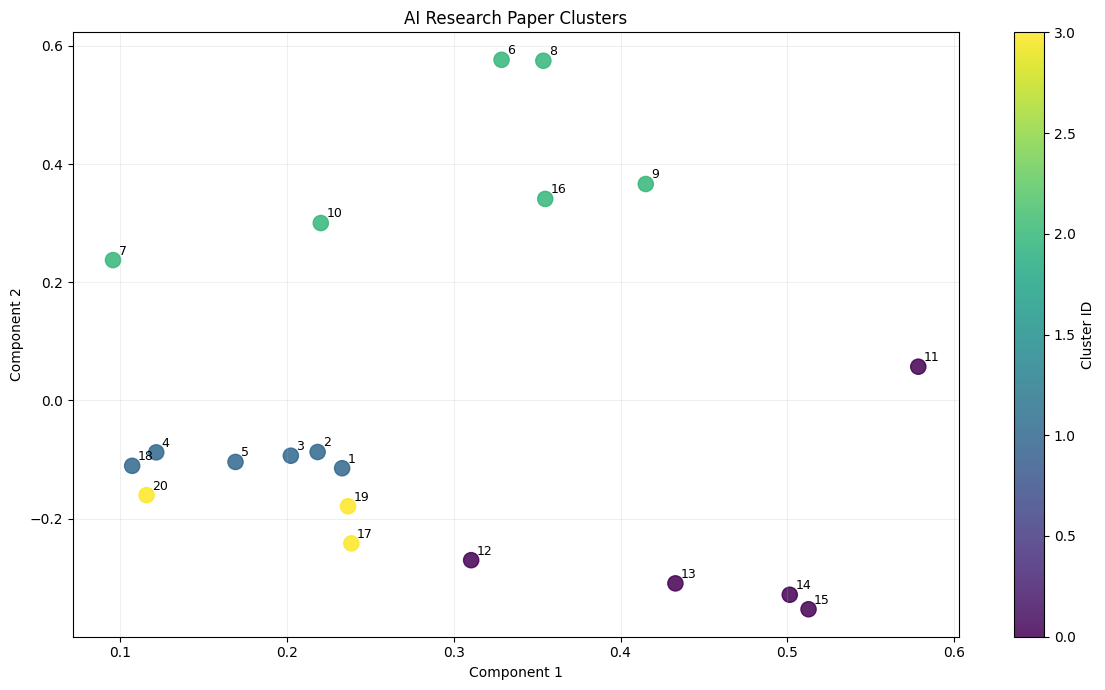

In [10]:

# Step 10: Visualize Research Paper Clusters

# Reduce paper features to 2 dimensions for plotting
svd_2d = TruncatedSVD(
    n_components=2,
    random_state=42
)

coords = svd_2d.fit_transform(X)

# Create the scatter plot
plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=df["cluster"],
    cmap="viridis",
    s=120,
    alpha=0.85
)

# Label each point with its paper ID
for i, paper_id in enumerate(df["paper_id"]):
    plt.annotate(
        str(paper_id),
        (coords[i, 0], coords[i, 1]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=9
    )

plt.colorbar(scatter, label="Cluster ID")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("AI Research Paper Clusters")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Citation Network Created Successfully!
Number of Papers: 20
Number of Citation Links: 30


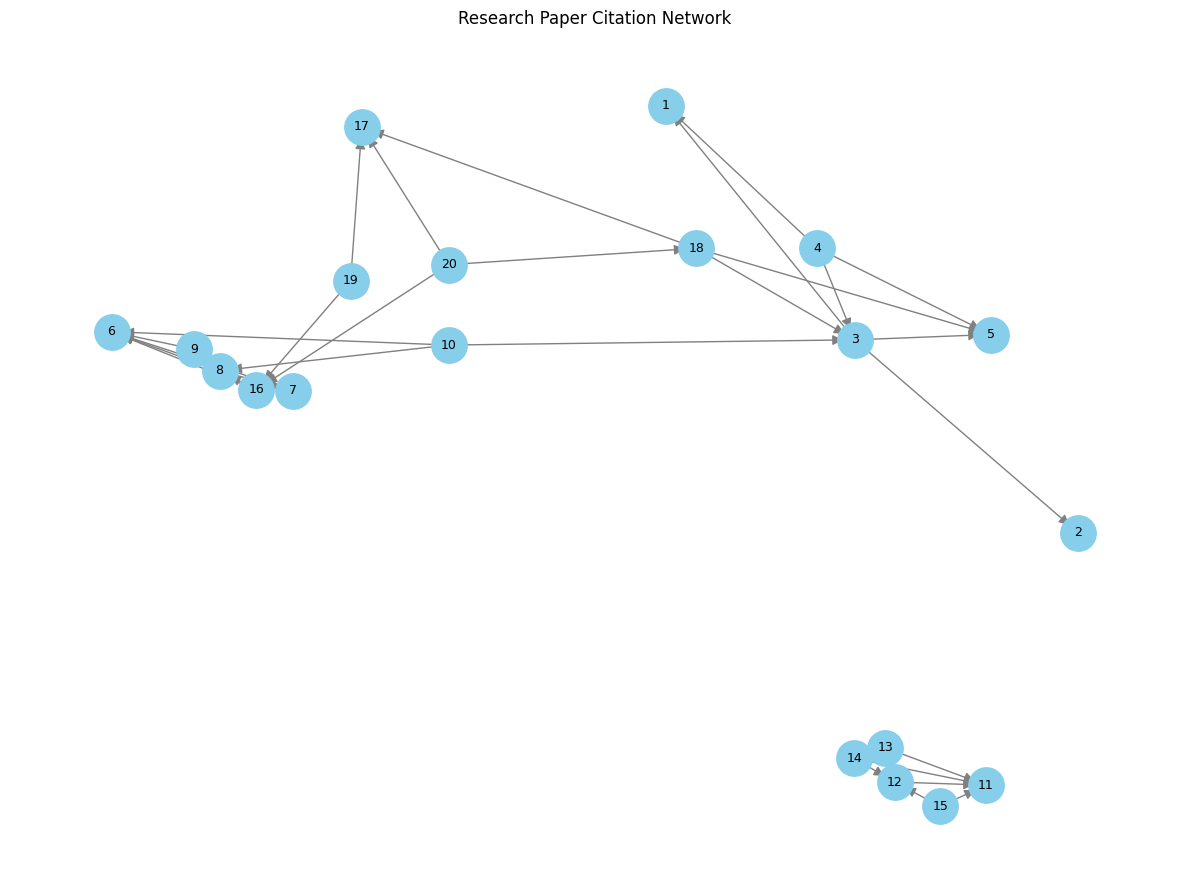

In [11]:

# Step 11: Build the Citation Network

G = nx.DiGraph()

# Add all research papers as nodes
G.add_nodes_from(df["paper_id"])

# Add citation relationships as directed edges
G.add_edges_from(
    zip(cites["citing"], cites["cited"])
)

print("Citation Network Created Successfully!")
print("Number of Papers:", G.number_of_nodes())
print("Number of Citation Links:", G.number_of_edges())

# Visualize the citation network
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G, pos,
    node_size=650,
    node_color="skyblue"
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=15,
    edge_color="gray"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9
)

plt.title("Research Paper Citation Network")
plt.axis("off")
plt.tight_layout()
plt.show()

In [12]:

# Step 12: Citation Analysis and PageRank

# Count incoming citations for each paper
citation_counts = dict(G.in_degree())

df["citations"] = (
    df["paper_id"]
    .map(citation_counts)
    .fillna(0)
    .astype(int)
)

# Calculate PageRank scores
pagerank_scores = nx.pagerank(G)

df["pagerank"] = (
    df["paper_id"]
    .map(pagerank_scores)
    .round(4)
)

# Display the 5 most cited papers
top_cited = df.sort_values(
    by=["citations", "pagerank"],
    ascending=[False, False]
).head(5)

print("Top 5 Most Cited Research Papers:")
display(
    top_cited[
        ["paper_id", "title", "citations", "pagerank"]
    ].reset_index(drop=True)
)

# Display the 5 highest PageRank papers
top_ranked = df.sort_values(
    by="pagerank",
    ascending=False
).head(5)

print("\nTop 5 Papers by PageRank:")
display(
    top_ranked[
        ["paper_id", "title", "citations", "pagerank"]
    ].reset_index(drop=True)
)

Top 5 Most Cited Research Papers:


,paper_id,title,citations,pagerank
0,6,Convolutional Networks for Image Classification,5,0.1461
1,11,Deep Q-Learning for Games,4,0.1163
2,12,Policy Gradient Methods for Control,3,0.0628
3,5,Named Entity Recognition in Text,3,0.0606
4,17,Predicting Patient Readmission,3,0.0572



Top 5 Papers by PageRank:


,paper_id,title,citations,pagerank
0,6,Convolutional Networks for Image Classification,5,0.1461
1,11,Deep Q-Learning for Games,4,0.1163
2,12,Policy Gradient Methods for Control,3,0.0628
3,5,Named Entity Recognition in Text,3,0.0606
4,17,Predicting Patient Readmission,3,0.0572


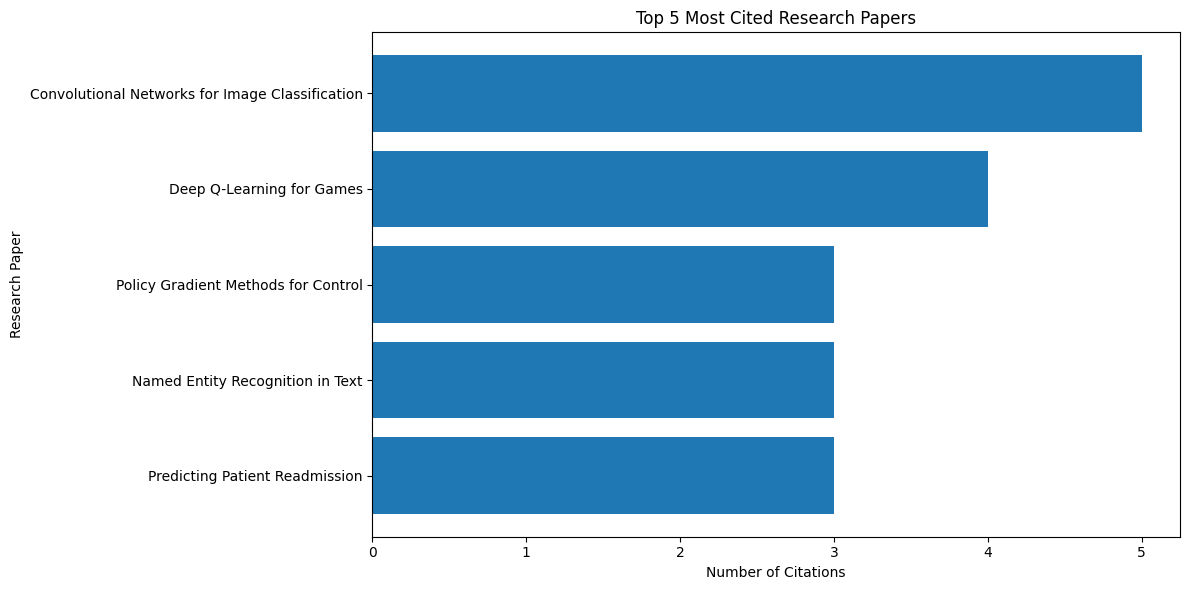

Citation chart saved successfully!


In [13]:

# Step 13: Visualize Top 5 Most Cited Papers

top_cited = df.sort_values(
    by=["citations", "pagerank"],
    ascending=[False, False]
).head(5)

plt.figure(figsize=(12, 6))

plt.barh(
    top_cited["title"],
    top_cited["citations"]
)

plt.xlabel("Number of Citations")
plt.ylabel("Research Paper")
plt.title("Top 5 Most Cited Research Papers")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("top_cited_papers.png", dpi=300)
plt.show()

print("Citation chart saved successfully!")

In [14]:

# Step 14: Generate Paper Intelligence Report

def paper_report(query, top_n=5):

    # Find relevant papers
    results = search_papers(query, top_n)

    # Add cluster and citation information
    results = results.merge(
        df[["paper_id", "cluster", "citations", "pagerank"]],
        on="paper_id",
        how="left"
    )

    return results


# Test the complete intelligence engine
query = "deep learning for medical images and disease prediction"

report = paper_report(query, top_n=5)

print("AI RESEARCH PAPER INTELLIGENCE REPORT")
print("=" * 60)
print("Search Query:", query)
print("Relevant Papers Found:", len(report))

display(report)

# Save report as CSV
report.to_csv("paper_intelligence_report.csv", index=False)

print("Report saved as paper_intelligence_report.csv")

AI RESEARCH PAPER INTELLIGENCE REPORT
Search Query: deep learning for medical images and disease prediction
Relevant Papers Found: 5


,paper_id,title,year,topic,similarity_score,cluster,citations,pagerank
0,16,Deep Learning for Medical Imaging,2017,Health,0.773,2,2,0.0472
1,9,Face Recognition Using Deep Features,2016,Vision,0.764,2,0,0.0276
2,8,Image Segmentation with Deep Networks,2018,Vision,0.749,2,2,0.0555
3,11,Deep Q-Learning for Games,2015,RL,0.697,0,4,0.1163
4,6,Convolutional Networks for Image Classification,2015,Vision,0.564,2,5,0.1461


Report saved as paper_intelligence_report.csv


In [15]:

# Step 15: Download Project Files

from google.colab import files

print("Choose a file to download:")

files.download("papers.csv")

Choose a file to download:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

from google.colab import files

files.download("citations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

from google.colab import files

files.download("paper_intelligence_report.csv")
files.download("top_cited_papers.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>